# Conditioning: what the data determine, and what training can resolve

> **Repository:** [PINNs-RL-PDE](https://github.com/josegarciav/PINNs-RL-PDE) · **Docs:** [Identifiability and conditioning](https://josegarciav.github.io/PINNs-RL-PDE/theory/identifiability/) · [API: analysis](https://josegarciav.github.io/PINNs-RL-PDE/api/analysis/)

Two different conditionings appear in a PINN inverse problem and `pinnrl.analysis` keeps them apart.

**1. The conditioning of the inverse problem**: how well the sensors determine the parameters. With observations $y_i = u(x_i, t_i;\theta) + \varepsilon_i$, $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$, it is measured by the Fisher information of the sensitivity Jacobian,

$$
J_{ij} = \frac{\partial u(x_i, t_i;\theta)}{\partial \theta_j}, \qquad F = \frac{1}{\sigma^2} J^\top J, \qquad \operatorname{Cov}(\hat\theta) \succeq F^{-1},
$$

whose eigenvectors are the parameter combinations the data determine well (large eigenvalue) or badly (small), and whose condition number $\kappa(F)$ bounds how much relative data error can grow into relative parameter error along the worst direction. No solver improves it; only new sensors or a prior do.

**Sensitivities from the trained network.** The network output does not depend on $\theta$ directly, so $J$ cannot be read off by autograd. At a minimum $w^\star(\theta)$ of the physics loss, $\nabla_w \mathcal{L}(w^\star(\theta), \theta) = 0$ for every $\theta$; differentiating this identity gives the implicit-function theorem,

$$
H_{ww}\, \frac{dw^\star}{d\theta} + H_{w\theta} = 0
\quad\Longrightarrow\quad
\frac{dw^\star}{d\theta} = -H_{ww}^{-1} H_{w\theta},
\qquad
J = \frac{\partial u_w}{\partial w}\bigg|_{w^\star} \frac{dw^\star}{d\theta},
$$

with $H_{ww} = \nabla^2_{ww}\mathcal{L}$ and $H_{w\theta} = \nabla_w \partial_\theta \mathcal{L}$. `surrogate_sensitivities` applies both blocks matrix-free by double backward, solves $(H_{ww} + \lambda I)\,\delta w = -H_{w\theta}$ by MINRES with a small damping $\lambda = 10^{-3}$ (the Hessian of a trained network is singular along flat directions and indefinite along a few, so conjugate gradient is not safe), and takes $J$ by a Jacobian-vector product through the network. **K01** checks the result against closed forms and a numerical reference.

**2. The conditioning of training**: how hard the optimizer's job is. Two spectra measure it. The **loss Hessian** $H = \nabla^2_{ww}\mathcal{L}$: gradient descent with step $\eta$ is stable only if $\eta < 2/\lambda_{\max}(H)$, and $\kappa(H) = \lambda_{\max}/\lambda_{\min}$ over the positive part sets its convergence rate; a negative eigenvalue says the point is not a minimum. `loss_hessian_spectrum` estimates the extreme eigenvalues by Lanczos iteration with Hessian-vector products. The **tangent kernel** of a loss term with per-point values $r(w) \in \mathbb{R}^M$,

$$
K = \nabla_w r\, \nabla_w r^\top \in \mathbb{R}^{M \times M}, \qquad \dot r = -\eta\, K\, r \ \text{ under gradient flow},
$$

whose eigenvalues are the rates at which the modes of that term are fitted. When the residual kernel's eigenvalues dwarf the boundary kernel's, the boundary term is fitted orders of magnitude more slowly: the gradient-pathology diagnosis of Wang, Teng & Perdikaris (2021) and the NTK view of Wang, Yu & Perdikaris (2022). `tangent_kernel_spectrum` assembles $K$ for any per-point term. **K03** surveys both spectra across operators and architectures.

This notebook first shows the tools live on a small problem, then reviews the two experiments from their raw results.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments"
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def load(exp):
    """The raw runs of an experiment (every seed, every cell), or None if it has not been run."""
    path = EXP / exp / "results" / "runs.json"
    if not path.exists():
        display(Markdown(f"> **{exp} has no results yet.** Run `python experiments/{exp}/run.py` first."))
        return None
    return json.loads(path.read_text())


def figure(exp, png, script="plot.py"):
    """Re-render an experiment's figure from its raw results with its own plot script, then show it."""
    if not (EXP / exp / "results").exists():
        display(Markdown(f"> **{exp} has no results yet**, so its figure cannot be rendered."))
        return
    subprocess.run([sys.executable, str(EXP / exp / script)], check=True, capture_output=True)
    display(Image(filename=str(EXP / exp / "results" / png), width=1100))


def table(header, rows):
    """A Markdown table from a header list and rows of already formatted strings."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def med_iqr(values):
    v = np.asarray(values, dtype=float)
    q25, q75 = np.percentile(v, [25, 75])
    return f"{np.median(v):.3f} [{q25:.3f}, {q75:.3f}]"


def readme(exp, section="Conclusion"):
    """Show one section of the experiment's README, so the notebook and the folder say the same thing."""
    text = (EXP / exp / "README.md").read_text()
    body = text.split(f"## {section}")[1].split("\n## ")[0] if f"## {section}" in text else ""
    display(Markdown(f"**{section} (from `experiments/{exp}/README.md`)**\n" + body))

## The tools, live

A heat problem ($u_t = \alpha u_{xx}$, $\alpha = 0.1$, $u = e^{-\alpha\pi^2 t}\sin\pi x$) trained for a few seconds. `closed_form_bound` needs no training: it differentiates the catalogue's closed form with respect to $\alpha$ by autograd on a per-point copy of the parameter, which is exact to floating point. `surrogate_sensitivities` needs the trained network and the problem it was trained on; it makes $\alpha$ trainable for the duration of the call, builds $H_{ww}$ and $H_{w\alpha}$ of the physics loss matrix-free, solves for $dw^\star/d\alpha$ with MINRES, and returns $J = \partial u_w / \partial\alpha$ at the requested points. The check is $J_{\text{surrogate}} \approx \partial u / \partial\alpha = -\pi^2 t\, u$.

In [2]:
import os, time
import torch
from pinnrl.analysis import closed_form_bound, exact_sensitivities, fisher_information, surrogate_sensitivities
from pinnrl.pdes.catalog import from_catalog

os.environ["TQDM_DISABLE"] = "1"
torch.manual_seed(0)
pde = from_catalog("heat")
trainer = pde.build_trainer(
    "feedforward", model={"hidden_dims": [32, 32, 32], "layer_norm": False},
    num_collocation_points=1024, batch_size=1024, num_boundary_points=256, num_initial_points=256,
    learning_rate=2e-3, scheduler_type="constant", early_stopping={"enabled": False},
    loss_weights={"residual": 1.0, "boundary": 10.0, "initial": 10.0},
)
t0 = time.time()
trainer.train_steps(num_steps=2000, resample_every=100)
print(f"trained in {time.time() - t0:.0f} s, relative L2 error {pde.validate(trainer.model)['l2_error']:.4f}")

trained in 9 s, relative L2 error 0.0078


surrogate sensitivities in 4.1 s: MINRES 300 iterations, residual 2.6e-03, damping 0.001
relative L2 difference to the closed form 0.020, correlation 0.9994


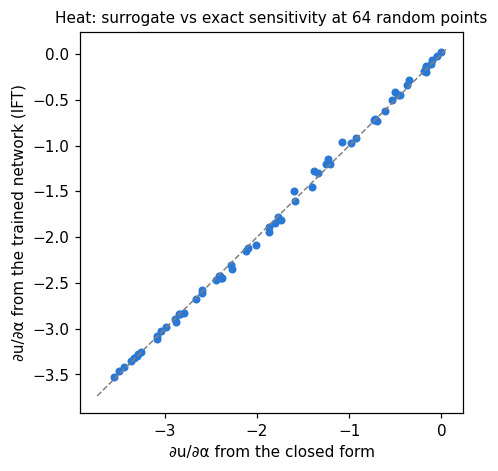

closed form  Cramér–Rao bound on std(α̂)/α at noise 0.05: 0.0299
surrogate    Cramér–Rao bound on std(α̂)/α at noise 0.05: 0.0298


In [3]:
torch.manual_seed(1)
x, t = torch.rand(64, 1), torch.rand(64, 1)
exact = exact_sensitivities(pde, ["alpha"], x, t)[:, 0, 0]
t0 = time.time()
sur = surrogate_sensitivities(pde, trainer.model, ["alpha"], x, t)
approx = sur.jacobian[:, 0, 0]
print(f"surrogate sensitivities in {time.time() - t0:.1f} s: MINRES {sur.cg_iterations[0]} iterations, residual {sur.cg_residuals[0]:.1e}, damping {sur.damping[0]:g}")
print(f"relative L2 difference to the closed form {float((approx - exact).norm() / exact.norm()):.3f}, correlation {float(torch.corrcoef(torch.stack([approx, exact]))[0, 1]):.4f}")
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(exact, approx, s=18, color="#2a78d6")
lim = [float(exact.min()) * 1.05, 0.05]
ax.plot(lim, lim, "--", color="gray", linewidth=1)
ax.set_xlabel("∂u/∂α from the closed form"); ax.set_ylabel("∂u/∂α from the trained network (IFT)")
ax.set_title("Heat: surrogate vs exact sensitivity at 64 random points", fontsize=10)
plt.show()
for name, J in [("closed form", exact), ("surrogate", approx)]:
    s = fisher_information(J[:, None], 0.05, ["alpha"])
    print(f"{name:<12} Cramér–Rao bound on std(α̂)/α at noise 0.05: {s.relative_std({'alpha': 0.1})['alpha']:.4f}")

The second tool: the extreme eigenvalues of the physics-loss Hessian $H$ at the trained weights, and the tangent kernels $K = \nabla_w r\,\nabla_w r^\top$ of the residual, boundary and initial terms on 64 points each. Read $\lambda_{\max}(H)$ as the learning-rate limit $\eta < 2/\lambda_{\max}$ of plain gradient descent (Adam's normalization relaxes it, but the ratio across problems is what K03 compares); a negative smallest Ritz value says the trained point is not an exact minimum, which is why the sensitivity solve needs an indefinite-capable solver; and compare the three kernel traces, which are the total rates at which each term is fitted.

Hessian (Lanczos, 60 steps, 0.4 s): largest 618, smallest -0.3, condition number of the positive part 4.75e+04; stable GD learning rate < 3.23e-03


| term | trace of K | largest eigenvalue | condition number |
|---|---|---|---|
| residual | 928 | 620 | 8.59e+07 |
| boundary | 1.58e+03 | 998 | 1.28e+07 |
| initial | 1.33e+03 | 1.08e+03 | 1.31e+07 |

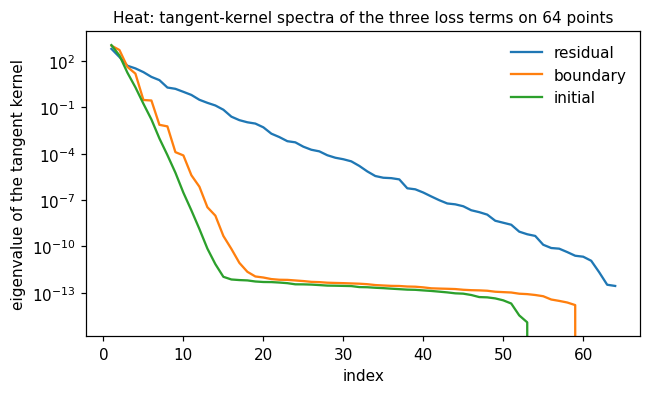

In [4]:
from pinnrl.analysis import loss_hessian_spectrum, tangent_kernel_spectrum

model = trainer.model
params = [p for p in model.parameters() if p.requires_grad]
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(0)
    xc, tc = pde.generate_collocation_points(1024)

def physics_loss():
    losses = pde.compute_loss(model, xc, tc)
    return losses["residual"] + 10 * losses["boundary"] + 10 * losses["initial"]

t0 = time.time()
hess = loss_hessian_spectrum(physics_loss, params, iterations=60)
print(f"Hessian (Lanczos, {hess.iterations} steps, {time.time() - t0:.1f} s): largest {hess.largest:.3g}, smallest {hess.smallest:.3g}, "
      f"condition number of the positive part {hess.condition_number():.3g}; stable GD learning rate < {2 / hess.largest:.2e}")

n = 64
xi, ti = torch.rand(n, 1), torch.rand(n, 1)
xb = torch.where(torch.rand(n, 1) < 0.5, 0.0, 1.0)
x0 = torch.rand(n, 1)
kernels = {
    "residual": tangent_kernel_spectrum(model, lambda m: pde.compute_residual(m, xi, ti)),
    "boundary": tangent_kernel_spectrum(model, lambda m: m(torch.cat([xb, ti], 1))),
    "initial": tangent_kernel_spectrum(model, lambda m: m(torch.cat([x0, torch.zeros(n, 1)], 1))),
}
table(["term", "trace of K", "largest eigenvalue", "condition number"],
      [[k, f"{v.trace:.3g}", f"{float(v.eigenvalues[0]):.3g}", f"{v.condition_number(1e-8 * float(v.eigenvalues[0])):.3g}"] for k, v in kernels.items()])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for k, v in kernels.items():
    ax.plot(np.arange(1, n + 1), v.eigenvalues.numpy(), label=k)
ax.set_yscale("log"); ax.set_xlabel("index"); ax.set_ylabel("eigenvalue of the tangent kernel"); ax.legend(frameon=False)
ax.set_title("Heat: tangent-kernel spectra of the three loss terms on 64 points", fontsize=10)
plt.show()

## K01: Fisher information from the trained surrogate, checked against the exact layer

**Question.** Which parameter combinations do the sensors determine, and can the trained network answer that without a closed form?

**What is compared.** For each problem a network is trained at the true parameters, $J_{\text{sur}}$ is computed by the implicit-function theorem at observation points, and three things are compared with a reference $J_{\text{ref}}$: the Jacobian itself, $\|J_{\text{sur}} - J_{\text{ref}}\| / \|J_{\text{ref}}\|$; the Cramér–Rao bounds $\sqrt{(F^{-1})_{jj}}$ from each; and for the two-parameter case the correlation $\rho$ and the condition number $\kappa(F)$.

- **Heat**, $\theta = \alpha$: reference $\partial u / \partial\alpha = -\pi^2 t\, u$; the F01 random layouts (20–1,000 points) and the F05 probe layouts (1–8 positions). Forward training, 5,000 steps.
- **KdV two-parameter**, $\theta = (\alpha, \beta)$, soliton $u = \frac{3}{\alpha}\operatorname{sech}^2(\tfrac12\sqrt{1/\beta}(x - t))$: reference by autograd of the closed form; 50–1,000 random points. Data-augmented training (the soliton collapses to $u = 0$ without data), 8,000 steps.
- **Burgers**, $\theta = \log\nu$ at $\nu = 0.01/\pi$: reference $\partial u/\partial\log\nu = \nu\,\partial u/\partial\nu$ by central differences of the Cole–Hopf solution at $\nu(1 \pm 1\,\%)$; 20–1,000 random nodes. Data-augmented training, 10,000 steps.

Noise $\sigma = 0.05$ throughout, 3 seeds.

In [5]:
runs = load("K01_fisher_information")
if runs:
    rows = []
    for rec in runs:
        for c in rec["cells"]:
            ex, su = c["exact"]["rel_std"], c["surrogate"]["rel_std"]
            names = list(ex)
            bound = " / ".join(f"{ex[k]:.3f}" for k in names)
            sbound = " / ".join(f"{su[k]:.3f}" for k in names)
            ratio = " / ".join(f"{su[k] / ex[k]:.2f}" for k in names)
            corr = f"{c['exact']['correlation'][0][1]:+.2f} / {c['surrogate']['correlation'][0][1]:+.2f}" if len(names) == 2 else "–"
            rows.append([rec["problem"], rec["seed"], f"{rec['l2_error']:.3f}", c["layout"], f"{c['jacobian_rel_error']:.3f}", bound, sbound, ratio, corr, f"{c['cg_residual']:.1e}"])
    table(["problem", "seed", "rel. L2 of u", "layout", "‖J_sur − J_ref‖ / ‖J_ref‖", "bound (ref)", "bound (surrogate)", "ratio", "correlation ref / sur", "solve residual"], rows)

| problem | seed | rel. L2 of u | layout | ‖J_sur − J_ref‖ / ‖J_ref‖ | bound (ref) | bound (surrogate) | ratio | correlation ref / sur | solve residual |
|---|---|---|---|---|---|---|---|---|---|
| heat | 0 | 0.038 | random_20 | 0.041 | 0.053 | 0.054 | 1.02 | – | 7.8e-03 |
| heat | 0 | 0.038 | random_50 | 0.057 | 0.037 | 0.038 | 1.04 | – | 7.8e-03 |
| heat | 0 | 0.038 | random_200 | 0.053 | 0.017 | 0.017 | 1.03 | – | 7.8e-03 |
| heat | 0 | 0.038 | random_1000 | 0.056 | 0.008 | 0.008 | 1.03 | – | 7.8e-03 |
| heat | 0 | 0.038 | sensors_1 | 0.032 | 0.012 | 0.013 | 1.03 | – | 7.8e-03 |
| heat | 0 | 0.038 | sensors_2 | 0.040 | 0.014 | 0.015 | 1.03 | – | 7.8e-03 |
| heat | 0 | 0.038 | sensors_4 | 0.047 | 0.016 | 0.016 | 1.03 | – | 7.8e-03 |
| heat | 0 | 0.038 | sensors_8 | 0.050 | 0.017 | 0.017 | 1.03 | – | 7.8e-03 |
| kdv_two_parameter | 0 | 0.006 | random_50 | 0.039 | 0.056 / 0.189 | 0.057 / 0.192 | 1.02 / 1.02 | +0.61 / +0.62 | 1.2e-04 |
| kdv_two_parameter | 0 | 0.006 | random_200 | 0.037 | 0.026 / 0.071 | 0.026 / 0.072 | 1.02 / 1.02 | +0.54 / +0.55 | 1.2e-04 |
| kdv_two_parameter | 0 | 0.006 | random_1000 | 0.037 | 0.014 / 0.034 | 0.015 / 0.035 | 1.02 / 1.01 | +0.64 / +0.64 | 1.2e-04 |
| burgers_log_nu | 0 | 0.028 | random_20 | 1.342 | 0.114 | 0.137 | 1.20 | – | 5.0e-03 |
| burgers_log_nu | 0 | 0.028 | random_50 | 1.808 | 0.123 | 0.077 | 0.62 | – | 5.0e-03 |
| burgers_log_nu | 0 | 0.028 | random_200 | 6.709 | 0.239 | 0.040 | 0.17 | – | 5.0e-03 |
| burgers_log_nu | 0 | 0.028 | random_1000 | 2.615 | 0.041 | 0.017 | 0.42 | – | 5.0e-03 |
| heat | 1 | 0.009 | random_20 | 0.018 | 0.048 | 0.049 | 1.01 | – | 2.6e-03 |
| heat | 1 | 0.009 | random_50 | 0.022 | 0.033 | 0.034 | 1.01 | – | 2.6e-03 |
| heat | 1 | 0.009 | random_200 | 0.025 | 0.018 | 0.018 | 1.02 | – | 2.6e-03 |
| heat | 1 | 0.009 | random_1000 | 0.025 | 0.008 | 0.008 | 1.02 | – | 2.6e-03 |
| heat | 1 | 0.009 | sensors_1 | 0.018 | 0.012 | 0.013 | 1.02 | – | 2.6e-03 |
| heat | 1 | 0.009 | sensors_2 | 0.019 | 0.014 | 0.015 | 1.02 | – | 2.6e-03 |
| heat | 1 | 0.009 | sensors_4 | 0.021 | 0.016 | 0.016 | 1.02 | – | 2.6e-03 |
| heat | 1 | 0.009 | sensors_8 | 0.023 | 0.017 | 0.017 | 1.02 | – | 2.6e-03 |
| kdv_two_parameter | 1 | 0.007 | random_50 | 0.051 | 0.063 / 0.163 | 0.064 / 0.167 | 1.02 / 1.02 | +0.68 / +0.69 | 1.6e-04 |
| kdv_two_parameter | 1 | 0.007 | random_200 | 0.053 | 0.032 / 0.081 | 0.033 / 0.082 | 1.02 / 1.01 | +0.65 / +0.66 | 1.6e-04 |
| kdv_two_parameter | 1 | 0.007 | random_1000 | 0.050 | 0.014 / 0.035 | 0.014 / 0.035 | 1.02 / 1.01 | +0.65 / +0.66 | 1.6e-04 |
| burgers_log_nu | 1 | 0.035 | random_20 | 24.176 | 4.434 | 0.189 | 0.04 | – | 6.9e-03 |
| burgers_log_nu | 1 | 0.035 | random_50 | 7.438 | 1.054 | 0.152 | 0.14 | – | 6.9e-03 |
| burgers_log_nu | 1 | 0.035 | random_200 | 3.996 | 0.111 | 0.034 | 0.30 | – | 6.9e-03 |
| burgers_log_nu | 1 | 0.035 | random_1000 | 3.219 | 0.055 | 0.018 | 0.32 | – | 6.9e-03 |
| heat | 2 | 0.026 | random_20 | 0.042 | 0.052 | 0.054 | 1.03 | – | 5.0e-03 |
| heat | 2 | 0.026 | random_50 | 0.040 | 0.034 | 0.035 | 1.03 | – | 5.0e-03 |
| heat | 2 | 0.026 | random_200 | 0.045 | 0.018 | 0.019 | 1.03 | – | 5.0e-03 |
| heat | 2 | 0.026 | random_1000 | 0.044 | 0.008 | 0.008 | 1.03 | – | 5.0e-03 |
| heat | 2 | 0.026 | sensors_1 | 0.025 | 0.012 | 0.013 | 1.02 | – | 5.0e-03 |
| heat | 2 | 0.026 | sensors_2 | 0.034 | 0.014 | 0.015 | 1.03 | – | 5.0e-03 |
| heat | 2 | 0.026 | sensors_4 | 0.040 | 0.016 | 0.016 | 1.03 | – | 5.0e-03 |
| heat | 2 | 0.026 | sensors_8 | 0.042 | 0.017 | 0.017 | 1.03 | – | 5.0e-03 |
| kdv_two_parameter | 2 | 0.005 | random_50 | 0.036 | 0.049 / 0.117 | 0.050 / 0.118 | 1.03 / 1.01 | +0.65 / +0.66 | 1.6e-04 |
| kdv_two_parameter | 2 | 0.005 | random_200 | 0.038 | 0.030 / 0.075 | 0.031 / 0.077 | 1.03 / 1.02 | +0.57 / +0.59 | 1.6e-04 |
| kdv_two_parameter | 2 | 0.005 | random_1000 | 0.039 | 0.013 / 0.032 | 0.014 / 0.033 | 1.03 / 1.01 | +0.62 / +0.63 | 1.6e-04 |
| burgers_log_nu | 2 | 0.056 | random_20 | 2.529 | 0.420 | 0.227 | 0.54 | – | 5.8e-03 |
| burgers_log_nu | 2 | 0.056 | random_50 | 14.957 | 1.474 | 0.105 | 0.07 | – | 5.8e-03 |
| burgers_log_nu | 2 | 0.056 | random_200 | 3.550 | 0.184 | 0.054 | 0.29 | – | 5.8e-03 |
| burgers_log_nu | 2 | 0.056 | random_1000 | 2.890 | 0.066 | 0.025 | 0.37 | – | 5.8e-03 |

/var/folders/yx/b_pyg98x1dj97pbflpck32d80000gn/T/ipykernel_15254/1691999380.py:11: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
/var/folders/yx/b_pyg98x1dj97pbflpck32d80000gn/T/ipykernel_15254/1691999380.py:11: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)


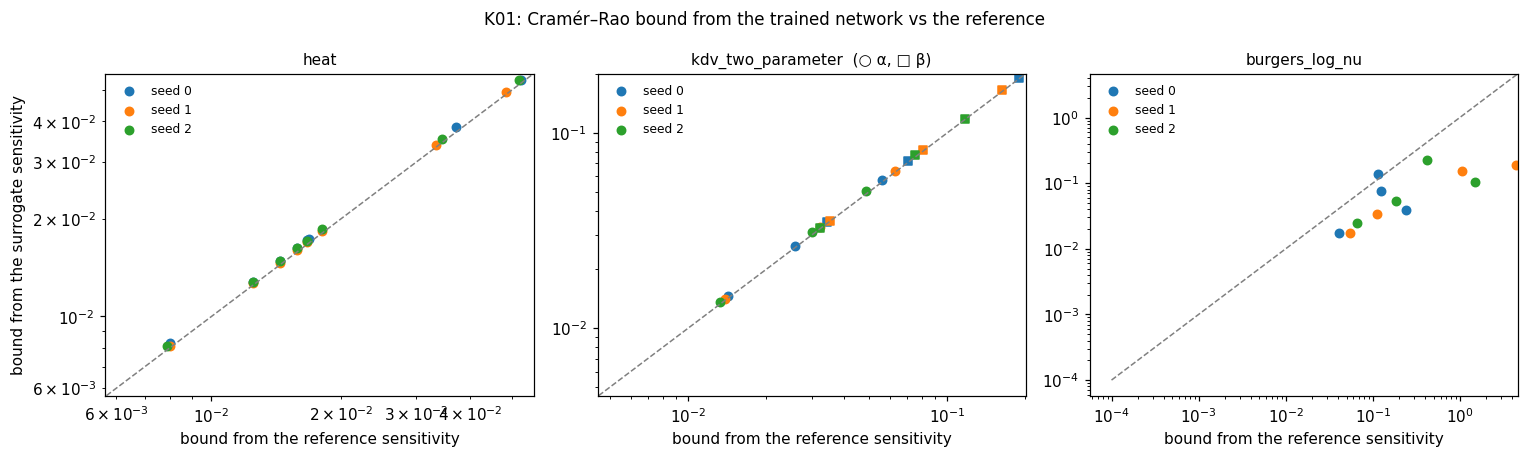

**Conclusion (from `experiments/K01_fisher_information/README.md`)**


1. **The surrogate's Fisher information is right when the surrogate resolves the solution.** On heat and the KdV soliton, with field errors below 4 %, the Jacobian by the implicit-function theorem agrees with the closed form to 2–6 %, and everything derived from it, the Cramér–Rao bounds, the α–β correlation and the condition number of $F$, agrees to 1–4 %. This is the validation the method needed before it is used on problems without a closed form, and it includes a genuinely two-parameter case with correlated estimates.
2. **It is wrong, and optimistic, when the surrogate smooths a feature it should resolve.** On Burgers at $\nu = 0.01/\pi$ the network's shock is wider than the true one (field error 3–6 %, concentrated at the shock), so its sensitivity to ν is spread over a wider region and is a different function from the reference's narrow spike: Jacobian errors of 1.3–24, and a bound 2–25× too small, which would claim more information about ν than the data carry. The direction of the error matters: a diagnostic that overstates identifiability is worse than one that understates it.
3. **The field error next to every surrogate bound is the condition to check.** The three problems order the same way by field error and by Jacobian error. `pinnrl.analysis` should report the two together, and the docs state the condition: the surrogate's Fisher information is trusted only where its forward error is small compared with the feature the parameter acts on.
4. **Sensor placement from the surrogate works where the surrogate is right.** The eight heat layouts (random counts and 1–8 probes) give the same ordering of bounds from the surrogate as from the closed form, so K02 can use the surrogate for problems without a closed form, with the proviso above.

**Consequences for the backlog:**
- K02 (sensor placement) proceeds on heat and KdV with the surrogate bound; for Burgers-type problems the shock must first be resolved (a sharper network, more collocation at the shock, or a numerical reference).
- F03 will show what the PINN estimate of ν actually does where the surrogate bound is unreliable.
- The Laplace approximation of roadmap item 5 reuses these Hessian blocks and inherits the same validity condition.


In [6]:
if runs:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
    for ax, problem in zip(axes, ["heat", "kdv_two_parameter", "burgers_log_nu"]):
        for rec in [r for r in runs if r["problem"] == problem]:
            for c in rec["cells"]:
                for k in c["exact"]["rel_std"]:
                    ax.scatter(c["exact"]["rel_std"][k], c["surrogate"]["rel_std"][k], s=30, color=f"C{rec['seed']}",
                               marker="o" if k in ("alpha", "log_nu") else "s", label=f"seed {rec['seed']}" if c is rec["cells"][0] and k in ("alpha", "log_nu") else None)
        lo = min(ax.get_xlim()[0], ax.get_ylim()[0]); hi = max(ax.get_xlim()[1], ax.get_ylim()[1])
        ax.plot([1e-4, 10], [1e-4, 10], "--", color="gray", linewidth=1)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        ax.set_title(problem + ("  (○ α, □ β)" if problem.startswith("kdv") else ""), fontsize=10)
        ax.set_xlabel("bound from the reference sensitivity"); ax.legend(frameon=False, fontsize=8)
    axes[0].set_ylabel("bound from the surrogate sensitivity")
    plt.suptitle("K01: Cramér–Rao bound from the trained network vs the reference", fontsize=11)
    plt.tight_layout(); plt.show()
    readme("K01_fisher_information")

## K03: is PINN training ill-conditioned by the differential operator?

**Hypothesis.** The residual of a $k$-th order operator applied to the network contains $k$-th derivatives of $u_w$, whose gradients with respect to the weights grow with the frequencies the network represents. The residual kernel $K_{\text{res}}$ should therefore have a larger trace and a worse condition number for higher-order operators, and the Hessian's $\lambda_{\max}$ should grow with the order, which forces a smaller learning rate and slows the fit of the boundary and initial terms whose kernels do not grow.

**Setup.** Eight catalogue problems spanning operator orders: convection ($u_t + c u_x = 0$, first order), heat / wave / Klein–Gordon / Poisson (second order, linear), the Burgers travelling wave and Allen–Cahn (second order, nonlinear), and the Euler–Bernoulli beam ($u_{tt} + u_{xxxx} = 0$, fourth order); two architectures (tanh MLP, Fourier features); two seeds; 3,000 Adam steps. For each run: the extreme Ritz values of the physics-loss Hessian (60 Lanczos steps), the tangent-kernel traces and condition numbers of the residual, boundary and initial terms on 96 points each, and the relative L2 error where a closed form exists.

In [7]:
runs = load("K03_training_conditioning")
if runs:
    rows = []
    for rec in sorted(runs, key=lambda r: (r["problem"], r["arch"], r["seed"])):
        h, k = rec["hessian"], rec["kernels"]
        ratio = k["residual"]["trace"] / k["boundary"]["trace"] if "boundary" in k and k["boundary"]["trace"] else float("nan")
        rows.append([rec["problem"], rec["arch"], rec["seed"], "–" if rec["l2_error"] is None else f"{rec['l2_error']:.3f}", f"{rec['final_loss']:.2e}",
                     f"{h['largest']:.3g}", f"{h['smallest']:.3g}", f"{h['condition_number']:.3g}", f"{ratio:.3g}", f"{k['residual']['condition_number']:.3g}"])
    table(["problem", "arch", "seed", "rel. L2", "final loss", "H: λ_max", "H: λ_min", "κ(H⁺)", "tr(K_res) / tr(K_bc)", "κ(K_res)"], rows)

| problem | arch | seed | rel. L2 | final loss | H: λ_max | H: λ_min | κ(H⁺) | tr(K_res) / tr(K_bc) | κ(K_res) |
|---|---|---|---|---|---|---|---|---|---|
| allen_cahn | feedforward | 0 | – | 8.27e-03 | 1.13e+03 | -0.116 | 2.8e+07 | 49 | 9.96e+07 |
| allen_cahn | feedforward | 1 | – | 1.21e-02 | 1.11e+03 | -1.61 | 1.84e+04 | 39.5 | 7.33e+07 |
| allen_cahn | fourier | 0 | – | 4.20e-03 | 578 | -0.112 | 1.8e+06 | 48.4 | 2.59e+07 |
| allen_cahn | fourier | 1 | – | 3.07e-03 | 627 | -0.498 | 1.66e+04 | 47.4 | 2.55e+05 |
| beam | feedforward | 0 | 0.052 | 6.35e-03 | 970 | -1.61 | 1.33e+07 | 0.717 | 6.77e+07 |
| beam | feedforward | 1 | 0.070 | 6.91e-03 | 956 | -4.11 | 9.13e+03 | 0.88 | 9.22e+07 |
| beam | fourier | 0 | 0.107 | 6.07e-02 | 1.39e+04 | -182 | 6.89e+05 | 2.31e+03 | 6.26e+06 |
| beam | fourier | 1 | 0.087 | 8.77e-02 | 4.96e+03 | -214 | 358 | 2.1e+03 | 6.07e+04 |
| burgers_travelling_wave | feedforward | 0 | 0.003 | 1.33e-04 | 458 | -0.165 | 9.65e+05 | 0.225 | 8.15e+07 |
| burgers_travelling_wave | feedforward | 1 | 0.002 | 1.46e-04 | 411 | -0.331 | 6.16e+05 | 0.434 | 9.19e+07 |
| burgers_travelling_wave | fourier | 0 | 0.003 | 8.94e-06 | 346 | -0.334 | 2.9e+06 | 46.6 | 761 |
| burgers_travelling_wave | fourier | 1 | 0.005 | 3.30e-03 | 320 | -1.12 | 1.26e+04 | 49.4 | 173 |
| convection | feedforward | 0 | 0.090 | 1.64e-02 | 6.13e+03 | -24.1 | 1.27e+04 | 0.56 | 9.44e+07 |
| convection | feedforward | 1 | 0.076 | 2.58e-02 | 4.79e+03 | -10.5 | 2.64e+07 | 0.313 | 9.29e+07 |
| convection | fourier | 0 | 0.015 | 6.25e-03 | 502 | -110 | 658 | 18.6 | 4.81e+04 |
| convection | fourier | 1 | 0.016 | 4.86e-03 | 356 | -26.3 | 2.04e+05 | 24.9 | 1.67e+04 |
| heat | feedforward | 0 | 0.026 | 3.64e-03 | 627 | -1.42 | 1.16e+06 | 0.808 | 8.58e+07 |
| heat | feedforward | 1 | 0.034 | 6.43e-03 | 698 | -1.76 | 2.05e+04 | 0.666 | 8.13e+07 |
| heat | fourier | 0 | 0.001 | 1.29e-05 | 146 | -0.0401 | 1.15e+06 | 33.5 | 8.25e+06 |
| heat | fourier | 1 | 0.001 | 7.49e-06 | 132 | -0.0421 | 1.9e+06 | 29.8 | 5.21e+05 |
| klein_gordon | feedforward | 0 | 0.040 | 4.15e-02 | 3.41e+03 | -8.52 | 9.39e+05 | 6.56 | 9.03e+07 |
| klein_gordon | feedforward | 1 | 0.057 | 1.17e-02 | 2.77e+03 | -8.16 | 3.23e+04 | 6.62 | 6.74e+07 |
| klein_gordon | fourier | 0 | 0.031 | 5.27e-02 | 1.46e+03 | -48.2 | 1.08e+04 | 1.79e+03 | 1.58e+04 |
| klein_gordon | fourier | 1 | 0.015 | 2.21e-02 | 1.59e+03 | -35.7 | 343 | 1.72e+03 | 3.63e+03 |
| poisson | feedforward | 0 | 0.028 | 1.56e-02 | 2.14e+03 | -4.78 | 2.4e+06 | 67 | 9.17e+07 |
| poisson | feedforward | 1 | 0.043 | 2.41e-02 | 2.75e+03 | -5.74 | 2.2e+06 | 73.4 | 7.82e+07 |
| poisson | fourier | 0 | 0.038 | 1.43e-01 | 3.57e+03 | -237 | 3.74e+04 | 3.97e+03 | 3.34e+04 |
| poisson | fourier | 1 | 0.021 | 1.18e-01 | 3.97e+03 | -280 | 1.05e+05 | 4.14e+03 | 5.5e+04 |
| wave | feedforward | 0 | 0.034 | 2.31e-02 | 2.76e+03 | -7.05 | 2.93e+05 | 5.34 | 9.68e+07 |
| wave | feedforward | 1 | 0.036 | 9.39e-02 | 2.14e+03 | -6.71 | 1.78e+05 | 7.27 | 9.94e+07 |
| wave | fourier | 0 | 0.042 | 5.17e-02 | 1.35e+03 | -34.8 | 371 | 1.67e+03 | 1.12e+04 |
| wave | fourier | 1 | 0.032 | 8.64e-02 | 1.49e+03 | -46.7 | 250 | 1.71e+03 | 4.11e+03 |

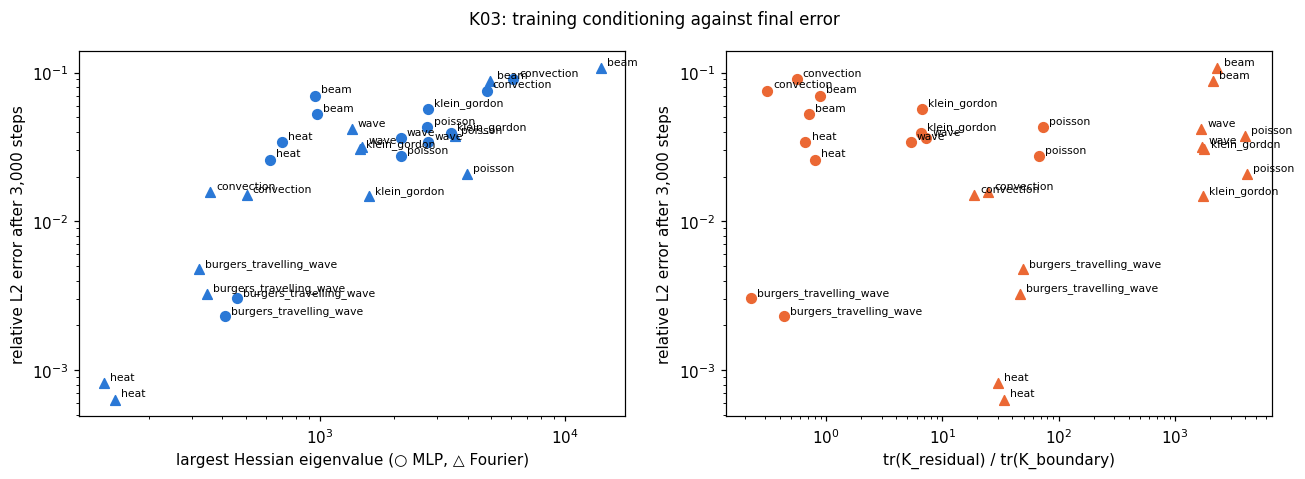

**Conclusion (from `experiments/K03_training_conditioning/README.md`)**


1. **The architecture, not the operator order, sets the conditioning at this budget.** For the MLP, $\lambda_{\max}$ is largest for first-order convection (5,459) and smaller for the fourth-order beam (963), and $\kappa(K_{\text{res}})$ is $8$–$10 \times 10^7$ for every problem. The residual kernel of a tanh MLP is ill-conditioned by the network's spectral bias, whatever operator is applied to it. The hypothesis is not supported.
2. **Fourier features fix the residual kernel and break the balance between terms.** $\kappa(K_{\text{res}})$ drops by three to five orders of magnitude (to $5 \times 10^2$ for the Burgers wave, $10^4$ for wave and Klein–Gordon), which is why they solve heat and convection 5–30× more accurately. The price is the trace ratio: the residual kernel's trace becomes $10^3$–$4 \times 10^3$ times the boundary kernel's on wave, Klein–Gordon, Poisson and the beam, the gradient pathology of Wang, Teng & Perdikaris (2021) in its pure form; on the beam it costs accuracy (0.097 vs 0.061). The random features inject high frequencies that a high-order derivative amplifies.
3. **No run is at a minimum.** Every Hessian has a negative Ritz value, from −0.0 (heat with Fourier features, essentially converged) to −258 (Poisson with Fourier features), and $|\lambda_{\min}|$ tracks the final loss across runs. It is a usable convergence diagnostic, and the reason the sensitivity solve of K01 needs an indefinite-capable solver.
4. **The learning-rate bound binds for Fourier features on high-order problems.** $2/\lambda_{\max}$ is $2 \times 10^{-4}$ for the Fourier beam and $5 \times 10^{-4}$ for Fourier Poisson, below the $10^{-3}$ used; Adam's normalization lets training proceed, but these are the two runs with the largest negative curvature and the worst accuracy relative to the MLP.

**Consequences for the backlog:**
- K04 (preconditioning, second-order optimizers) should target the MLP's $\kappa(K_{\text{res}}) \sim 10^8$, which is architecture-wide, and the Fourier trace imbalance, which the adaptive loss weights in `pinnrl` address and K03 can now measure.
- The diagnostics cost 0.3–5 s per run and are worth recording at every study checkpoint next to the loss.
- The operator-order question is re-asked after D01/D02 (a settled optimizer); at 3,000 steps the answer is dominated by where the optimizer is.


In [8]:
if runs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    for rec in runs:
        if rec["l2_error"] is None:
            continue
        m = "o" if rec["arch"] == "feedforward" else "^"
        axes[0].scatter(rec["hessian"]["largest"], rec["l2_error"], marker=m, s=40, color="#2a78d6")
        axes[0].annotate(rec["problem"], (rec["hessian"]["largest"], rec["l2_error"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
        k = rec["kernels"]
        ratio = k["residual"]["trace"] / k["boundary"]["trace"]
        axes[1].scatter(ratio, rec["l2_error"], marker=m, s=40, color="#eb6834")
        axes[1].annotate(rec["problem"], (ratio, rec["l2_error"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
    for ax, xl in zip(axes, ["largest Hessian eigenvalue (○ MLP, △ Fourier)", "tr(K_residual) / tr(K_boundary)"]):
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(xl); ax.set_ylabel("relative L2 error after 3,000 steps")
    plt.suptitle("K03: training conditioning against final error", fontsize=11)
    plt.tight_layout(); plt.show()
    readme("K03_training_conditioning")

## What to take from the two experiments

- The surrogate's Fisher information is trustworthy **when the surrogate resolves the solution**: on heat and the KdV soliton it reproduces the bound, the correlation and the condition number from the reference to a few percent. On the Burgers shock, which the network smooths, it is off by an order of magnitude and in the optimistic direction. The field error reported next to every surrogate bound is the condition to check first.
- Training conditioning is a property of the **operator and the architecture**, not of the data; the Hessian's largest eigenvalue and the kernel trace ratios say which problems need a smaller learning rate, loss re-weighting or a different architecture before any identification is attempted.